# Detecção de defeito mousebite em PCB

### Parâmetros da execução

| Variável       | Tipo                          | Descrição                                  |
| -------------- | ----------------------------- | ------------------------------------------ |
| `group_id`     | `str`                         | Identificador numérico do grupo de imagens |
| `img_id`       | `str`                         | Identificador numérico da imagem           |
| `images_repo`  | `Path \| None`                | Caminho do repositório de imagens          |
| `pipeline_cfg` | `PCBDetectionPipelineConfigs` | Configurações do pipeline                  |

Se não informado caminho local do repositório de imagens, o programa tenta fazer 
download das imagens indicadas.

In [1]:
from pathlib import Path

from config import ImageRegistrationConfig, PCBDetectionPipelineConfigs, RegistrationAlgorithm

group_id = "00041"
img_id = "00041003"
images_repo = Path("/path/to/repo/DeepPCB/PCBData")
pipeline_cfg = PCBDetectionPipelineConfigs(
    registration=ImageRegistrationConfig(
        algorithm=RegistrationAlgorithm.FFT_CROSS_CORRELATION
    )
)

In [2]:
from jupyter_utils import run_pipeline


result_set = run_pipeline(
    group_id,
    img_id,
    from_local_fs=True,
    cfg=pipeline_cfg
)

Carregando imagens
  Matriz: /path/to/repo/DeepPCB/PCBData/group00041/00041/00041003_temp.jpg
  Resultado: /path/to/repo/DeepPCB/PCBData/group00041/00041/00041003_test.jpg
Convertendo imagens para escala de cinza
Realizando registro translacional por correlação cruzada via FFT
  Resultado:
    dx=1
    dy=1
    métrica=0.9701743662772614
Aplicando transformações para alinhamento das imagens
Buscando defeitos
  Identificados 5 defeitos
Categorizando defeitos
  Mantidos 2 de 5 defeitos
Gravando resultados
  Imagem matriz: /path/to/repo/pcb-defect-detector/output/reference.png
  Imagem registrada: /path/to/repo/pcb-defect-detector/output/registered.png
  Imagem com diferença: /path/to/repo/pcb-defect-detector/output/difference.png
  Imagem com limiar: /path/to/repo/pcb-defect-detector/output/threshold.png
  Imagem com defeitos: /path/to/repo/pcb-defect-detector/output/defects.png
  Imagem com defeitos classificados: /path/to/repo/pcb-defect-detector/output/classified_defects.png
Processo 

## Relatório de execução

### Tempo de execução por etapa

| Etapa | Tempo (s) | % do total |
|---|---:|---:|
| Carregamento e escala de cinza | 0.007 | 5.0% |
| Registro de imagens | 0.108 | 74.8% |
| Identificação de defeitos | 0.008 | 5.6% |
| Classificação de defeitos | 0.002 | 1.4% |
| Gravação de resultados | 0.019 | 13.3% |
| **Total** | **0.144** | **100%** |

### Resultado do pipeline

#### 0. Imagem matriz

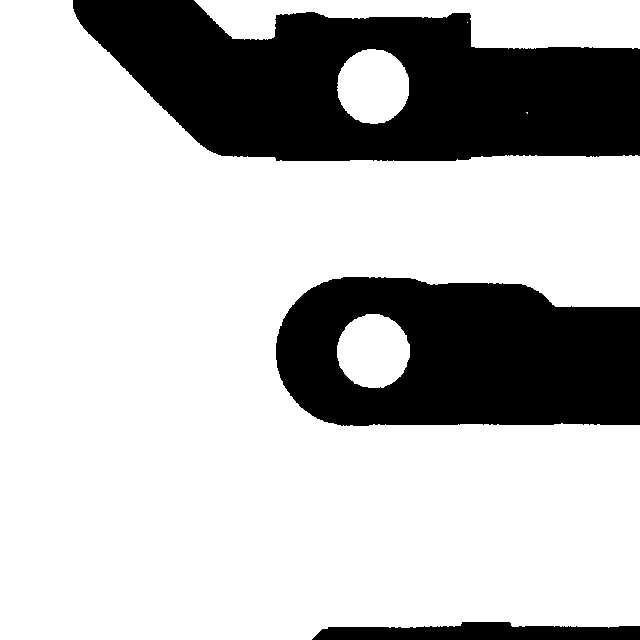

#### 1. Imagem registrada

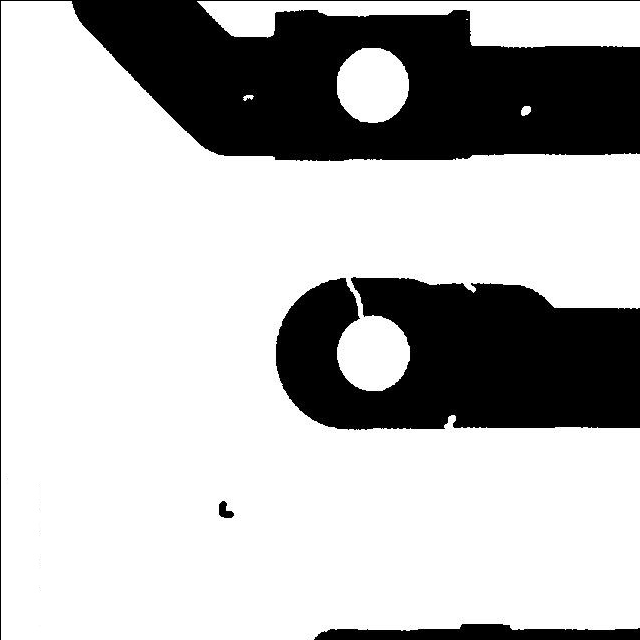

#### 2. Imagem de diferença

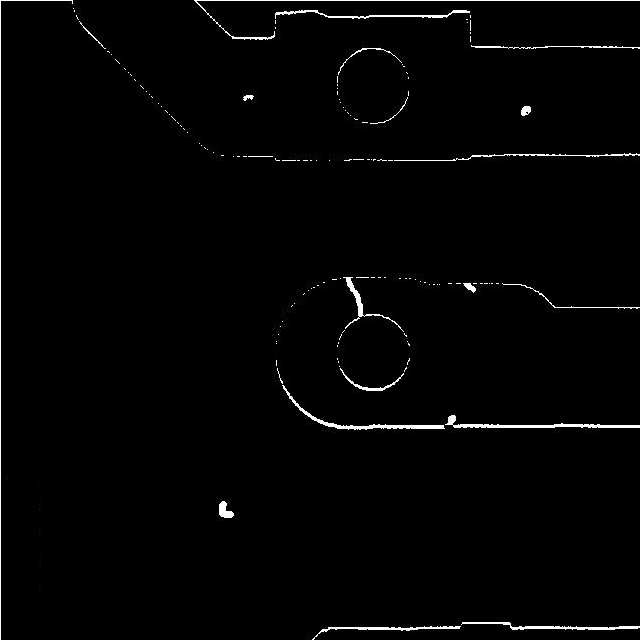

#### 3. Imagem de limiar

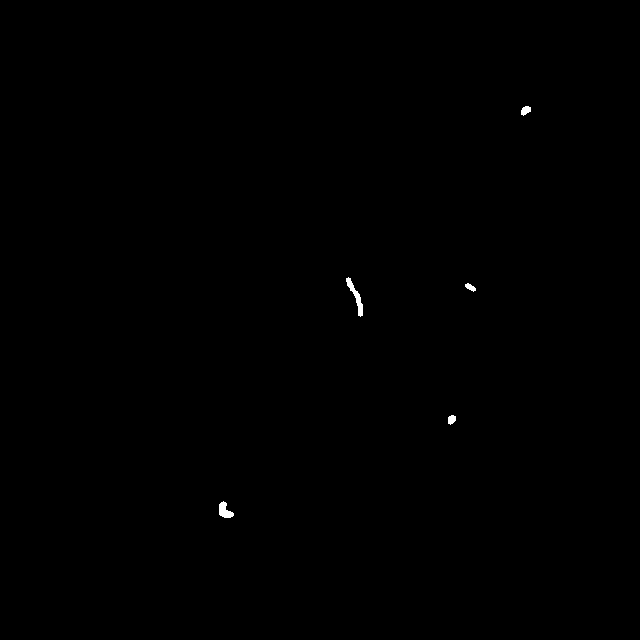

#### 4. Imagem com defeitos identificados

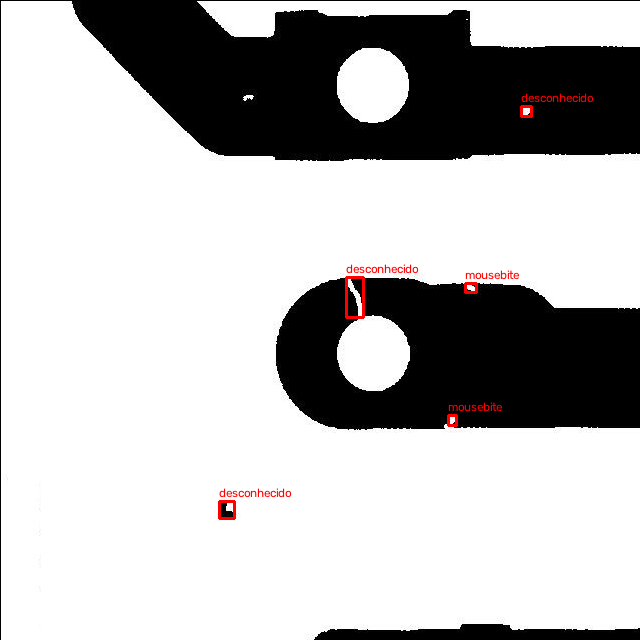

#### 5. Imagem com defeitos mousebite identificados

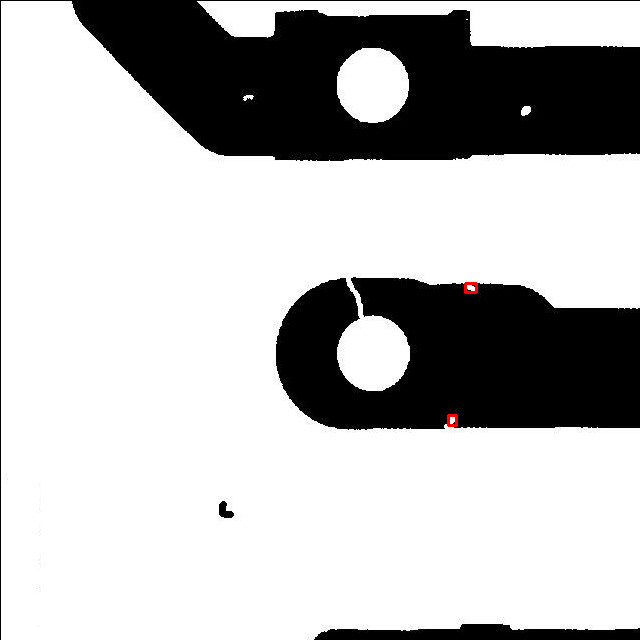

In [3]:
from jupyter_utils import display_results


display_results(result_set)